In [11]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path

# ── paths ────────────────────────────────────────────────────────────────────
INTERP = Path('/n/holylfs06/LABS/kempner_project_b/Lab/dendritic/adivm/dendritic-modeling/outputs/interpretability_results')
FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)

TAGS   = {'2×2': 'fc7_2x2_ne4096', '3×3×3': 'fc7_3x3x3_ne4096'}
COLORS = {'2×2': '#2a78d6', '3×3×3': '#1baf7a'}   # palette slots 1 & 2

# ── plot style ───────────────────────────────────────────────────────────────
GRID    = '#e1e0d9'
INK2    = '#52514e'
MUTED   = '#898781'
SURFACE = '#fcfcfb'

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.spines.left': True,  'axes.spines.bottom': True,
    'axes.edgecolor': '#c3c2b7', 'axes.linewidth': 0.8,
    'grid.color': GRID, 'grid.linewidth': 0.5, 'axes.grid': True, 'axes.axisbelow': True,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.labelsize': 9,  'ytick.labelsize': 9,
    'axes.labelcolor': INK2, 'axes.labelsize': 10,
    'legend.framealpha': 0.9, 'legend.edgecolor': GRID, 'legend.fontsize': 9,
    'font.family': 'sans-serif',
})

# diverging cmap: blue (neuron is important, ablation hurts) ↔ red (ablation helps)
DIV_CMAP = LinearSegmentedColormap.from_list('abl', ['#2a78d6', '#f0efec', '#e34948'])

In [12]:
# ── load all saved .npy files ─────────────────────────────────────────────────
data = {}
for label, tag in TAGS.items():
    d = INTERP / tag
    data[label] = {
        'fc8_proj':       np.load(d / 'fc8_weight_projection.npy'),      # (N_E, 1000)
        'activations':    np.load(d / 'val_activations.npy'),             # (50K, N_E)
        'labels':         np.load(d / 'val_labels.npy'),                  # (50K,)
        'mean_act':       np.load(d / 'per_class_mean_act.npy'),          # (N_E, 1000)
        'sel_idx':        np.load(d / 'selectivity_index.npy'),           # (N_E,)
        'top_by_weight':  np.load(d / 'top_classes_by_weight.npy'),       # (N_E, 10)
        'top_by_act':     np.load(d / 'top_classes_by_activation.npy'),   # (N_E, 10)
        'baseline_acc':   np.load(d / 'baseline_class_acc.npy'),          # (1000,)
        'abl_delta':      np.load(d / 'ablation_acc_delta.npy'),          # (N_E, 1000)
    }
    ne = data[label]['fc8_proj'].shape[0]
    print(f"{label}  N_E={ne}  baseline top-1={data[label]['baseline_acc'].mean()*100:.2f}%")

2×2  N_E=4096  baseline top-1=51.51%
3×3×3  N_E=4096  baseline top-1=51.58%


## Figure 1 — Selectivity index distribution (Analysis 2)
Lifetime sparseness per neuron: 0 = responds equally to all classes, 1 = responds to exactly one class.

2×2  median SI=0.082  mean=0.086  frac>0.9=0.0%
3×3×3  median SI=0.075  mean=0.079  frac>0.9=0.0%


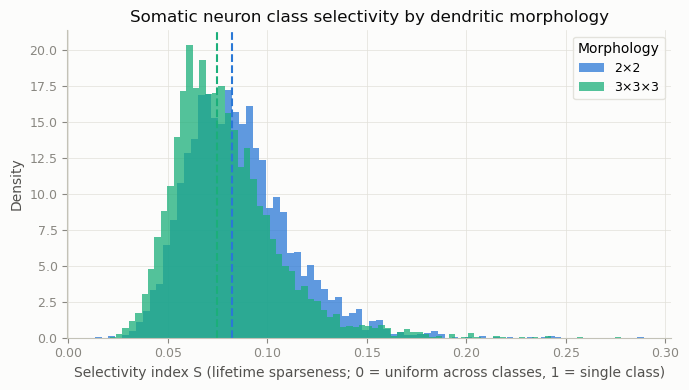

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))

for label, d in data.items():
    si = d['sel_idx']
    ax.hist(si, bins=80, color=COLORS[label], alpha=0.75, label=label,
            histtype='stepfilled', edgecolor='none', density=True)
    ax.axvline(np.median(si), color=COLORS[label], lw=1.5, ls='--')
    print(f"{label}  median SI={np.median(si):.3f}  mean={si.mean():.3f}  "
          f"frac>0.9={( si>0.9).mean()*100:.1f}%")

ax.set_xlabel('Selectivity index S (lifetime sparseness; 0 = uniform across classes, 1 = single class)')
ax.set_ylabel('Density')
ax.set_title('Somatic neuron class selectivity by dendritic morphology', color='#0b0b0b')
ax.legend(title='Morphology')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig1_selectivity_index.png', bbox_inches='tight', dpi=200)
plt.show()

## Figure 2 — FC8 weight peakedness (Analysis 1)
For each neuron: `max|w| / mean|w|`. High = one dominant class in the readout; low = broad mixed tuning.

2×2  median peak-ratio=4.8  mean=5.0
3×3×3  median peak-ratio=4.7  mean=4.9


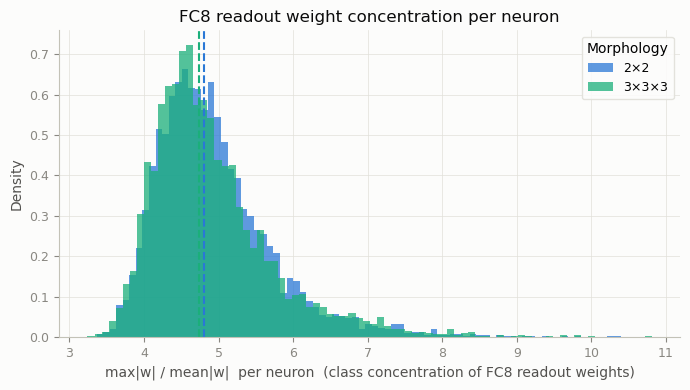

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))

for label, d in data.items():
    W = np.abs(d['fc8_proj'])                                    # (N_E, 1000)
    peak = W.max(axis=1) / (W.mean(axis=1) + 1e-10)             # (N_E,)
    ax.hist(peak, bins=80, color=COLORS[label], alpha=0.75, label=label,
            histtype='stepfilled', edgecolor='none', density=True)
    ax.axvline(np.median(peak), color=COLORS[label], lw=1.5, ls='--')
    print(f"{label}  median peak-ratio={np.median(peak):.1f}  mean={peak.mean():.1f}")

ax.set_xlabel('max|w| / mean|w|  per neuron  (class concentration of FC8 readout weights)')
ax.set_ylabel('Density')
ax.set_title('FC8 readout weight concentration per neuron', color='#0b0b0b')
ax.legend(title='Morphology')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig2_weight_peakedness.png', bbox_inches='tight', dpi=200)
plt.show()

## Figure 3 — Top-class agreement: weight vs activation (Analysis 1 + 2)
For each neuron: does the class it most strongly drives via fc8 weight match the class it most responds to by mean activation?

2×2  top-1 match=0.6%  top-1 in top-10 act=3.9%
3×3×3  top-1 match=1.1%  top-1 in top-10 act=6.1%


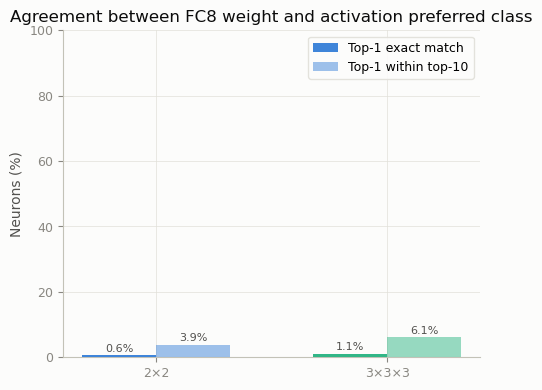

In [15]:
K = data['2x2']['top_by_weight'].shape[1] if '2x2' in data else data['2×2']['top_by_weight'].shape[1]

labels_list, top1_agree, topk_agree = [], [], []
for label, d in data.items():
    tw = d['top_by_weight']   # (N_E, K)
    ta = d['top_by_act']      # (N_E, K)
    K  = tw.shape[1]
    top1 = (tw[:, 0] == ta[:, 0]).mean()
    topk = np.array([tw[i, 0] in ta[i] for i in range(tw.shape[0])]).mean()
    labels_list.append(label)
    top1_agree.append(top1 * 100)
    topk_agree.append(topk * 100)
    print(f"{label}  top-1 match={top1*100:.1f}%  top-1 in top-{K} act={topk*100:.1f}%")

x = np.arange(len(labels_list))
w = 0.32
fig, ax = plt.subplots(figsize=(5, 4))
bars1 = ax.bar(x - w/2, top1_agree, width=w, label='Top-1 exact match',
               color=[COLORS[l] for l in labels_list], alpha=0.9, zorder=3)
bars2 = ax.bar(x + w/2, topk_agree, width=w, label=f'Top-1 within top-{K}',
               color=[COLORS[l] for l in labels_list], alpha=0.45, zorder=3)
for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=8, color=INK2)
ax.set_xticks(x); ax.set_xticklabels(labels_list)
ax.set_ylabel('Neurons (%)')
ax.set_ylim(0, 100)
ax.set_title('Agreement between FC8 weight and activation preferred class', color='#0b0b0b')
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig3_topclass_agreement.png', bbox_inches='tight', dpi=200)
plt.show()

## Figure 4 — FC8 weight matrix, neurons sorted by preferred class (Analysis 1)
Neurons sorted by argmax class weight. Diagonal structure indicates class-specialized readout weights; absence of diagonal indicates distributed coding.

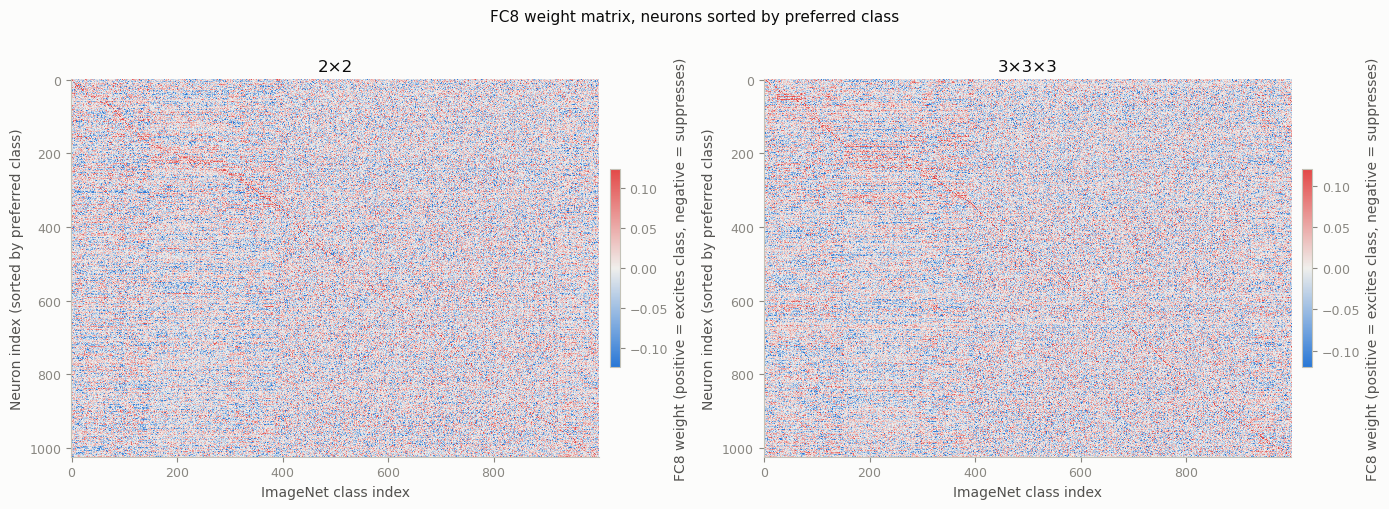

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (label, d) in zip(axes, data.items()):
    W = d['fc8_proj']                              # (N_E, 1000) — signed weights
    order    = np.argsort(W.argmax(axis=1))        # sort neurons by preferred class
    W_sorted = W[order][::4]                       # subsample every 4th -> 1024 rows

    vmax = np.percentile(np.abs(W_sorted), 99)
    im = ax.imshow(W_sorted, aspect='auto', cmap=DIV_CMAP,
                   vmin=-vmax, vmax=vmax, interpolation='nearest')
    ax.set_xlabel('ImageNet class index')
    ax.set_ylabel('Neuron index (sorted by preferred class)')
    ax.set_title(label, color='#0b0b0b')
    ax.grid(False)
    plt.colorbar(im, ax=ax, fraction=0.018, pad=0.02,
                 label='FC8 weight (positive = excites class, negative = suppresses)')

plt.suptitle('FC8 weight matrix, neurons sorted by preferred class',
             fontsize=11, color='#0b0b0b', y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig4_fc8_weight_heatmap.png', bbox_inches='tight', dpi=200)
plt.show()

## Figure 5 — Ablation: total impact per neuron (Analysis 3)
For each neuron: `sum of |Δacc|` across all 1000 classes when that neuron is zeroed. Which neurons are most critical overall?

2×2  median=2.500  top-5 neurons: [3.9399998 3.9       3.8000002 3.7799997 3.62     ]
3×3×3  median=2.400  top-5 neurons: [4.24      3.5600002 3.4999998 3.4800005 3.4000003]


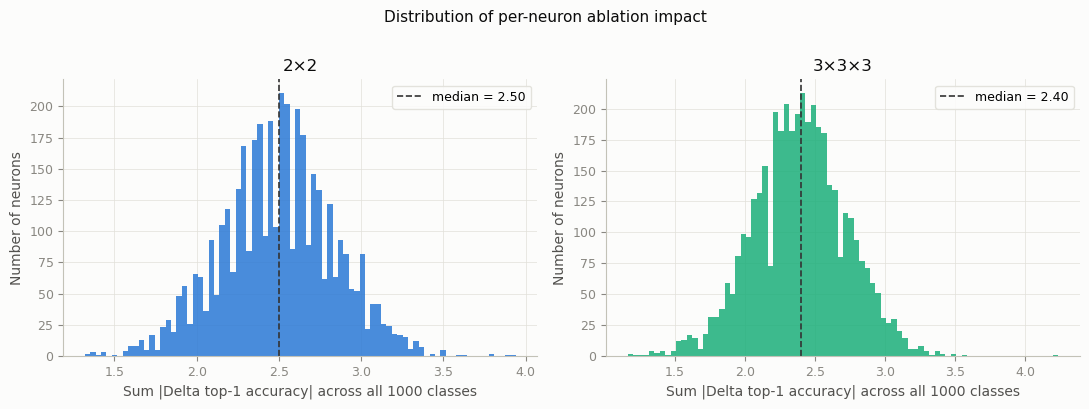

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (label, d) in zip(axes, data.items()):
    total_impact = np.abs(d['abl_delta']).sum(axis=1)   # (N_E,)
    ax.hist(total_impact, bins=80, color=COLORS[label], alpha=0.85,
            histtype='stepfilled', edgecolor='none')
    med = np.median(total_impact)
    ax.axvline(med, color='#333', lw=1.2, ls='--', label=f'median = {med:.2f}')
    top5 = np.sort(total_impact)[-5:][::-1]
    print(f"{label}  median={med:.3f}  top-5 neurons: {top5}")
    ax.set_xlabel('Sum |Delta top-1 accuracy| across all 1000 classes')
    ax.set_ylabel('Number of neurons')
    ax.set_title(label, color='#0b0b0b')
    ax.legend()

plt.suptitle('Distribution of per-neuron ablation impact',
             fontsize=11, color='#0b0b0b', y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig5_ablation_per_neuron.png', bbox_inches='tight', dpi=200)
plt.show()

## Figure 6 — Ablation: per-class sensitivity (Analysis 3)
For each ImageNet class: total `|Δacc|` summed across all neurons. Classes with high totals rely on many neurons; low totals = robust distributed coding.

2×2  most sensitive=76.781  least=0.000  mean=10.227
3×3×3  most sensitive=101.620  least=0.000  mean=9.793


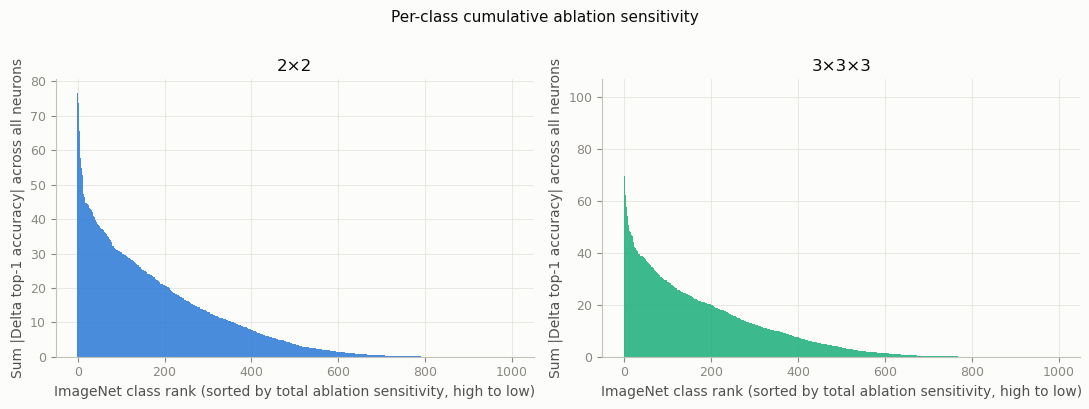

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (label, d) in zip(axes, data.items()):
    class_sensitivity = np.abs(d['abl_delta']).sum(axis=0)    # (1000,)
    sorted_sens = np.sort(class_sensitivity)[::-1]
    ax.bar(np.arange(1000), sorted_sens, width=1.0, color=COLORS[label], alpha=0.85, edgecolor='none')
    ax.set_xlabel('ImageNet class rank (sorted by total ablation sensitivity, high to low)')
    ax.set_ylabel('Sum |Delta top-1 accuracy| across all neurons')
    ax.set_title(label, color='#0b0b0b')
    print(f"{label}  most sensitive={sorted_sens[0]:.3f}  "
          f"least={sorted_sens[-1]:.3f}  mean={sorted_sens.mean():.3f}")

plt.suptitle('Per-class cumulative ablation sensitivity',
             fontsize=11, color='#0b0b0b', y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig6_ablation_per_class.png', bbox_inches='tight', dpi=200)
plt.show()

## Figure 7 — Selectivity vs ablation impact scatter (Analysis 2 + 3)
Does a more class-selective neuron (high SI) also have greater impact when ablated? Tests whether selectivity predicts functional importance.

2×2  Pearson r(SI, ablation_impact) = -0.5371
3×3×3  Pearson r(SI, ablation_impact) = -0.5262


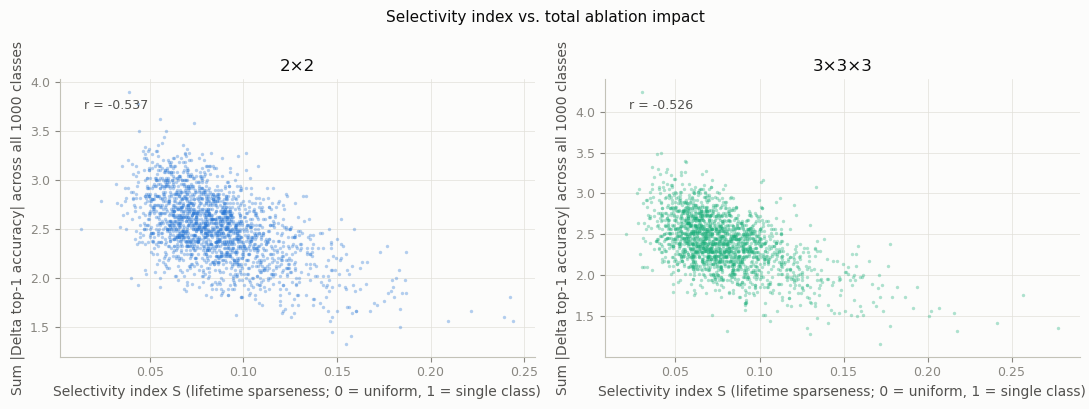

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (label, d) in zip(axes, data.items()):
    si     = d['sel_idx']                              # (N_E,)
    impact = np.abs(d['abl_delta']).sum(axis=1)        # (N_E,)

    rng = np.random.default_rng(0)
    idx = rng.choice(len(si), size=min(2000, len(si)), replace=False)

    ax.scatter(si[idx], impact[idx], s=6, alpha=0.35, color=COLORS[label],
               linewidths=0, rasterized=True)

    r = np.corrcoef(si, impact)[0, 1]
    ax.text(0.05, 0.93, f'r = {r:.3f}', transform=ax.transAxes,
            fontsize=9, color=INK2, va='top')
    ax.set_xlabel('Selectivity index S (lifetime sparseness; 0 = uniform, 1 = single class)')
    ax.set_ylabel('Sum |Delta top-1 accuracy| across all 1000 classes')
    ax.set_title(label, color='#0b0b0b')
    print(f"{label}  Pearson r(SI, ablation_impact) = {r:.4f}")

plt.suptitle('Selectivity index vs. total ablation impact',
             fontsize=11, color='#0b0b0b', y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig7_selectivity_vs_impact.png', bbox_inches='tight', dpi=200)
plt.show()

## Figure 8 — Ablation delta heatmap (Analysis 3)
Blue = neuron is important for this class (ablation hurts accuracy). Red = neuron was suppressing this class (ablation helps). Neurons sorted by their most-damaged class.

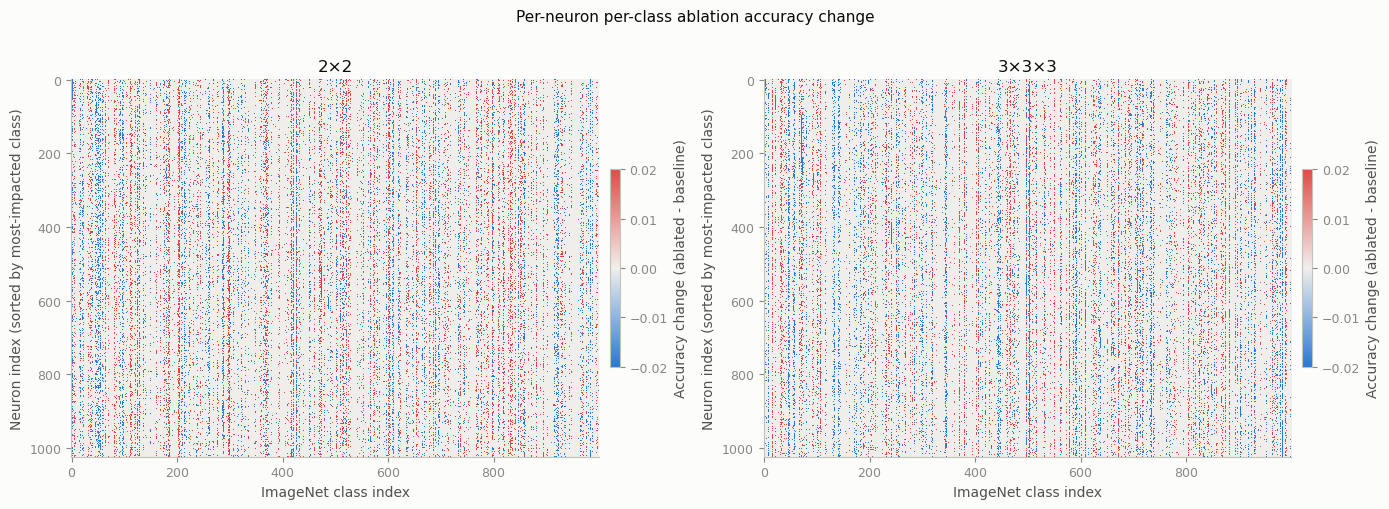

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (label, d) in zip(axes, data.items()):
    D = d['abl_delta']                                     # (N_E, 1000)
    order = np.argsort(D.argmin(axis=1))                   # sort by class most hurt
    D_sorted = D[order][::4]                               # subsample to 1024 rows

    vmax = np.percentile(np.abs(D_sorted), 98)
    im = ax.imshow(D_sorted, aspect='auto', cmap=DIV_CMAP,
                   vmin=-vmax, vmax=vmax, interpolation='nearest')
    ax.set_xlabel('ImageNet class index')
    ax.set_ylabel('Neuron index (sorted by most-impacted class)')
    ax.set_title(label, color='#0b0b0b')
    ax.grid(False)
    plt.colorbar(im, ax=ax, fraction=0.018, pad=0.02, label='Accuracy change (ablated - baseline)')

plt.suptitle('Per-neuron per-class ablation accuracy change',
             fontsize=11, color='#0b0b0b', y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig8_ablation_heatmap.png', bbox_inches='tight', dpi=200)
plt.show()